<a href="https://colab.research.google.com/github/dharumahendra/vision-azure/blob/main/vision_senpro_dharu.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [22]:
!pip install azure-ai-vision-imageanalysis pillow matplotlib requests

In [23]:
from azure.ai.vision.imageanalysis import ImageAnalysisClient
from azure.ai.vision.imageanalysis.models import VisualFeatures
from azure.core.credentials import AzureKeyCredential
from azure.core.exceptions import HttpResponseError
from google.colab import userdata

VISION_KEY = userdata.get('VISION_KEY')
VISION_ENDPOINT = userdata.get('VISION_ENDPOINT')

client = ImageAnalysisClient(endpoint=VISION_ENDPOINT,
                             credential=AzureKeyCredential(VISION_KEY))

In [24]:
IMAGE_PATH = "foto objek.jpg"  # sesuaikan dengan nama file yang diupload

try:
    with open(IMAGE_PATH, "rb") as f:
        result = client.analyze(
            image_data=f.read(),
            visual_features=[VisualFeatures.CAPTION, VisualFeatures.TAGS,
                             VisualFeatures.OBJECTS, VisualFeatures.READ],
            gender_neutral_caption=True,
        )
except HttpResponseError as e:
    print("Error:", e.status_code, e.reason, e.message)

In [25]:
# Caption (deskripsi gambar)
if result.caption:
    print(f"Caption: '{result.caption.text}' ({result.caption.confidence:.2%})")

# Tags
print("\nTags:")
for tag in result.tags.list:
    print(f"  {tag.name} ({tag.confidence:.2%})")

# Objek terdeteksi
print("\nObjects:")
for obj in result.objects.list:
    print(f"  {obj.tags[0].name} ({obj.tags[0].confidence:.2%}) box={obj.bounding_box}")

# Teks (OCR)
print("\nText (OCR):")
if result.read:
    for block in result.read.blocks:
        for line in block.lines:
            print("  ", line.text)

Caption: 'a green stuffed animal on a desk with a drink' (74.25%)

Tags:
  indoor (97.68%)
  soft drink (89.93%)
  plush (88.05%)
  stuffed toy (88.03%)
  stuffed (87.89%)
  drink (87.82%)
  furniture (84.58%)
  text (83.68%)
  cup (65.36%)
  chocolate (60.99%)

Objects:
  monitor (52.40%) box={'x': 0, 'y': 64, 'w': 121, 'h': 236}
  computer keyboard (58.70%) box={'x': 12, 'y': 308, 'w': 171, 'h': 84}
  chair (62.10%) box={'x': 274, 'y': 217, 'w': 234, 'h': 306}

Text (OCR):
   0


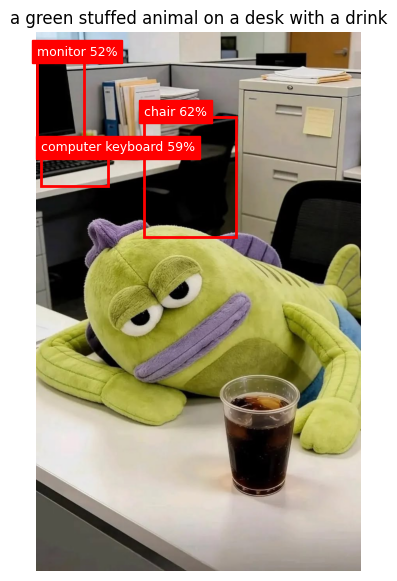

In [26]:
import requests, io
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

img = Image.open(IMAGE_PATH)
fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(img)
for obj in result.objects.list:
    b = obj.bounding_box
    ax.add_patch(patches.Rectangle((b.x, b.y), b.width, b.height,
                                   fill=False, edgecolor='red', linewidth=2))
    ax.text(b.x, b.y - 5, f"{obj.tags[0].name} {obj.tags[0].confidence:.0%}",
            color='white', backgroundcolor='red', fontsize=9)
ax.set_title(result.caption.text if result.caption else "Object Detection")
ax.axis('off')
plt.show()

a green stuffed animal on a desk with a drink (74%) box={'x': 0, 'y': 0, 'w': 828, 'h': 1375}
a glass of soda with ice (69%) box={'x': 456, 'y': 861, 'w': 214, 'h': 320}
a green and purple stuffed animal next to a drink (77%) box={'x': 0, 'y': 451, 'w': 809, 'h': 610}
a close up of a stuffed animal (83%) box={'x': 235, 'y': 649, 'w': 307, 'h': 241}
a close up of a keyboard (86%) box={'x': 0, 'y': 296, 'w': 197, 'h': 83}
a black rectangular object with a white background (66%) box={'x': 0, 'y': 67, 'w': 107, 'h': 215}
a blurry image of a white cup (75%) box={'x': 109, 'y': 241, 'w': 53, 'h': 56}
a close up of a stuffed animal (82%) box={'x': 180, 'y': 574, 'w': 253, 'h': 201}
a file cabinet with a yellow sticky note (77%) box={'x': 505, 'y': 82, 'w': 314, 'h': 479}
a stack of papers on a shelf (78%) box={'x': 312, 'y': 129, 'w': 113, 'h': 159}


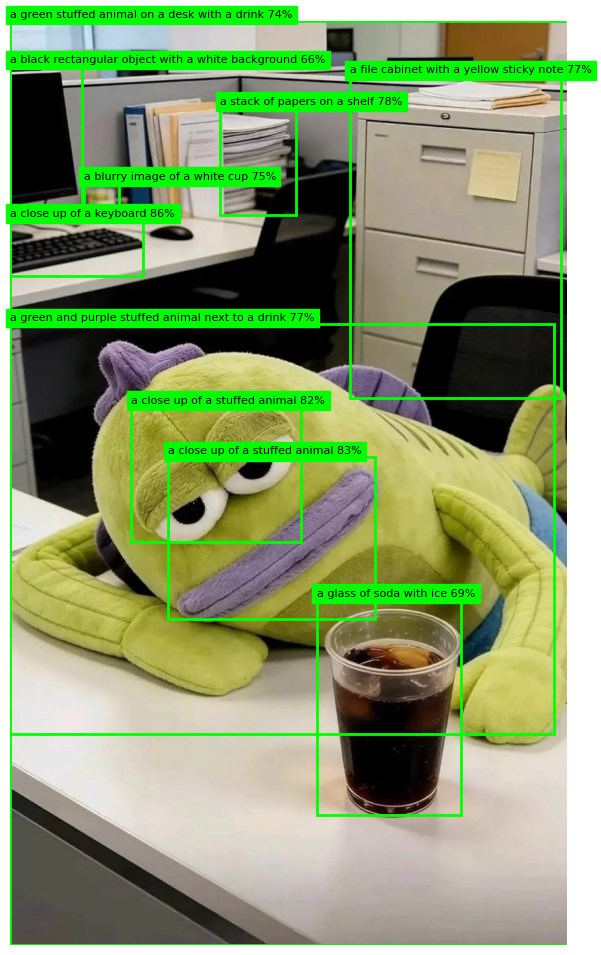

In [27]:
with open(IMAGE_PATH, "rb") as f:
    result_dc = client.analyze(image_data=f.read(),
                               visual_features=[VisualFeatures.DENSE_CAPTIONS])

img = Image.open(IMAGE_PATH)
fig, ax = plt.subplots(figsize=(10, 12))
ax.imshow(img)
for cap in result_dc.dense_captions.list:
    print(f"{cap.text} ({cap.confidence:.0%}) box={cap.bounding_box}")
    b = cap.bounding_box
    ax.add_patch(patches.Rectangle((b.x, b.y), b.width, b.height,
                                   fill=False, edgecolor='lime', linewidth=2))
    ax.text(b.x, b.y - 5, f"{cap.text} {cap.confidence:.0%}",
            color='black', backgroundcolor='lime', fontsize=8)
ax.axis('off')
plt.show()